# JS10 - Lab 4
## Day and Night Classification with ANN

Klasifikasi citra **siang (day)** dan **malam (night)** menggunakan ANN yang dilatih pada fitur
**HOG (Histogram of Oriented Gradients)**.

Alur: unduh dataset -> muat citra -> *resize* & encoding label -> ekstraksi fitur HOG ->
standardisasi -> split train/validation -> bangun ANN -> latih -> evaluasi -> simpan model.

### Step 0 - Download the Dataset

Dataset citra day/night diambil dari modul JS06 Lab 5. Sel di bawah mengunduh `images.zip`
(~29 MB) dan mengekstraknya ke folder `images/` bila belum ada. Jika folder `images/` sudah
tersedia, unduhan dilewati.

In [1]:
import urllib.request
import zipfile
from pathlib import Path

URL = ("https://3048497142-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F"
       "YHOv2XH8FJMJSMsnhwNa%2Fuploads%2F9IvI7imHRxFYT9gtRGh7%2Fimages.zip?alt=media&"
       "token=d1bc0a22-4056-4a11-a801-04f245ee0e62")

if Path("images/training").exists() and Path("images/test").exists():
    print("Dataset sudah tersedia, unduhan dilewati.")
else:
    zip_path = Path("images.zip")
    if not zip_path.exists():
        print("Mengunduh dataset ...")
        urllib.request.urlretrieve(URL, zip_path)
        print("Selesai:", round(zip_path.stat().st_size / 1e6, 1), "MB")

    with zipfile.ZipFile(zip_path) as z:
        members = [n for n in z.namelist() if n.startswith("images/") and n.endswith(".jpg")]
        z.extractall(".", members=members)
    print("Ekstrak selesai:", len(members), "citra")

n_train = sum(1 for _ in Path("images/training").rglob("*.jpg"))
n_test = sum(1 for _ in Path("images/test").rglob("*.jpg"))
print(f"Training: {n_train} citra | Test: {n_test} citra")

Dataset sudah tersedia, unduhan dilewati.
Training: 240 citra | Test: 160 citra


### Step 1 - Import Libraries

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

# Deterministic training so the reported metrics are reproducible
tf.keras.utils.set_random_seed(42)

### Step 2 - Load Dataset

In [3]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "images/training/"
test_dir  = "images/test/"

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print("Train:", len(train_img), "| Test:", len(test_img))
print("Contoh label:", train_img[0][1])

Train: 240 | Test: 160
Contoh label: day


### Step 3 - Pre-processing

Seluruh citra di-*resize* ke **256x256** agar dimensinya seragam, lalu label di-encode:
`day = 1`, `night = 0`.

In [4]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

print("Jumlah data latih:", len(X_train_img))
print("Ukuran citra     :", X_train_img[0].shape)
print("Distribusi label :", dict(zip(*np.unique(y_train, return_counts=True))))

Jumlah data latih: 240
Ukuran citra     : (256, 256, 3)
Distribusi label : {np.int64(0): np.int64(120), np.int64(1): np.int64(120)}


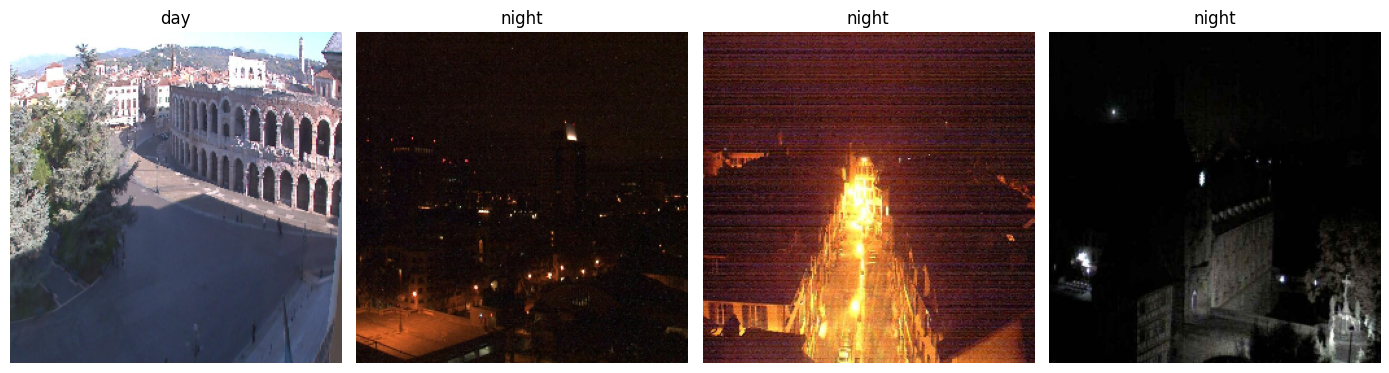

In [5]:
# Visual inspection of a few preprocessed images
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, i in zip(axes, np.random.default_rng(0).choice(len(X_train_img), 4, replace=False)):
    ax.imshow(X_train_img[i])
    ax.set_title('day' if y_train[i] == 1 else 'night')
    ax.axis('off')
plt.tight_layout()
plt.show()

### Step 4 - Feature Extraction

**HOG** merangkum distribusi arah gradien pada sel-sel citra. Dengan `pixels_per_cell=(8,8)`,
`cells_per_block=(2,2)`, dan 9 orientasi pada citra 256x256, dihasilkan
`31 x 31 x 2 x 2 x 9 = 34.596` fitur per citra.

Referensi: <https://scikit-image.org/docs/0.25.x/auto_examples/features_detection/plot_hog.html>

In [6]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

print("Fitur latih:", X_train_feat.shape)
print("Fitur uji  :", X_test_feat.shape)

Fitur latih: (240, 34596)
Fitur uji  : (160, 34596)


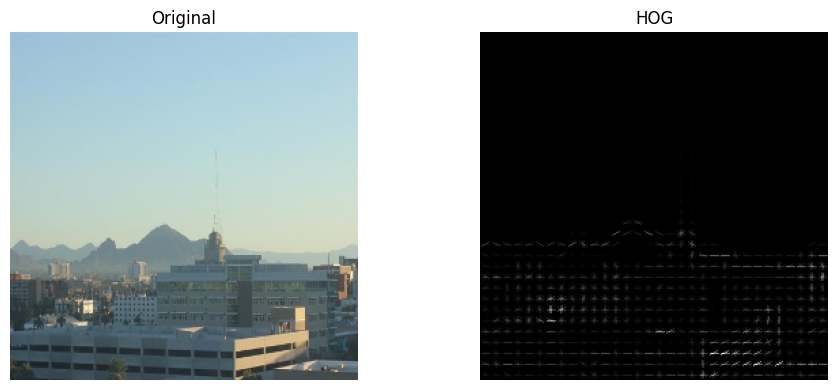

In [7]:
# Visualize the HOG descriptor of one image
gray = cv2.cvtColor(X_train_img[0], cv2.COLOR_RGB2GRAY)
_, hog_image = hog(gray, orientations=9, pixels_per_cell=(8,8), cells_per_block=(2,2),
                   block_norm='L2-Hys', visualize=True, feature_vector=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(X_train_img[0]); axes[0].set_title('Original'); axes[0].axis('off')
axes[1].imshow(hog_image, cmap='gray'); axes[1].set_title('HOG'); axes[1].axis('off')
plt.tight_layout()
plt.show()

### Step 5 - Feature Standardization

In [8]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print("Mean setelah scaling (mendekati 0):", round(float(X_train_scaled.mean()), 4))

Mean setelah scaling (mendekati 0): 0.0


### Step 6 - Create Training and Validation Data

In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

# Convert labels to numpy arrays
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test_scaled.shape)

Train: (192, 34596) | Val: (48, 34596) | Test: (160, 34596)


### Step 7 - Construct the ANN Model

Arsitektur sesuai modul:

* Input layer - 34.596 fitur HOG
* Hidden layer 1 - 128 neuron, ReLU
* Hidden layer 2 - 64 neuron, ReLU
* Output layer - 1 neuron, sigmoid (klasifikasi biner)

Catatan: deskripsi modul menyebut output "2 nodes - Sigmoid", namun kode yang dipakai adalah
**1 neuron sigmoid** dengan `binary_crossentropy` - bentuk yang benar untuk klasifikasi biner.

In [10]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

### Step 8 - Train the Model

In [11]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=2
)

Epoch 1/20


6/6 - 5s - 760ms/step - accuracy: 0.7969 - loss: 0.9021 - val_accuracy: 0.9792 - val_loss: 0.0387


Epoch 2/20


6/6 - 1s - 89ms/step - accuracy: 0.9896 - loss: 0.0167 - val_accuracy: 1.0000 - val_loss: 0.0013


Epoch 3/20


6/6 - 1s - 85ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 0.0043


... (30 outputs left out)

Epoch 19/20


6/6 - 0s - 78ms/step - accuracy: 1.0000 - loss: 5.9818e-07 - val_accuracy: 1.0000 - val_loss: 0.0042


Epoch 20/20


6/6 - 0s - 75ms/step - accuracy: 1.0000 - loss: 5.7065e-07 - val_accuracy: 1.0000 - val_loss: 0.0042


### Step 9 - Evaluate the Model with Test Data

In [12]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print("Test loss    :", round(test_loss, 4))
print("Test Accuracy:", round(test_acc, 4))

Test loss    : 1.0839
Test Accuracy: 0.9375


### Step 10 - Generate a Model Performance Report

In [13]:
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=['night', 'day']))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

       night       0.91      0.97      0.94        80
         day       0.97      0.90      0.94        80

    accuracy                           0.94       160
   macro avg       0.94      0.94      0.94       160
weighted avg       0.94      0.94      0.94       160

[[78  2]
 [ 8 72]]


### Step 11 - Visualize the Training Process

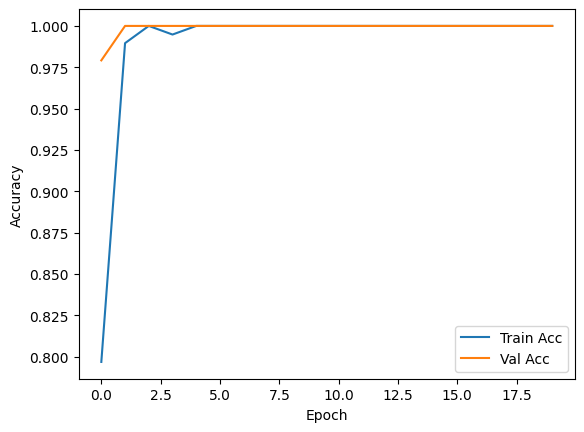

In [14]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

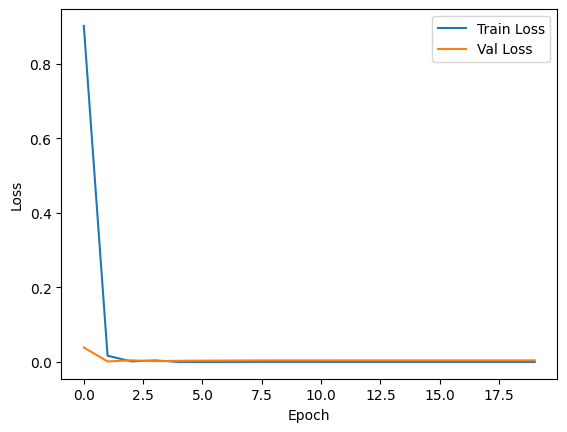

In [15]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

### Step 12 - Interpretation of the Training Curve

Dengan seed tetap, hasil pelatihan bersifat reprodusibel. Yang terlihat pada plot:

* Akurasi latih naik cepat dan mencapai **1.0000** pada epoch ke-5, dan akurasi validasi juga
  mencapai **1.0000** sejak epoch ke-2. Pada data sekecil ini (192 citra latih, 48 validasi)
  kedua kurva mudah menyentuh nilai maksimum.
* Meskipun akurasi validasi 1.0, **loss validasi naik** dari 0.0013 (epoch ke-2) menjadi 0.0042
  (epoch ke-20) - tanda model makin "yakin" pada data latih tetapi keyakinannya makin tidak
  terkalibrasi untuk data baru. Ini bentuk awal overfitting yang tidak terlihat dari akurasi saja.
* Buktinya muncul pada data uji: akurasi **0.9375**, dengan 8 citra *day* diprediksi *night* dan
  2 citra *night* diprediksi *day*.
* Penyebab strukturalnya adalah **jumlah parameter jauh melebihi jumlah data**: hidden layer
  pertama saja berisi 34.596 x 128 = ~4.4 juta parameter untuk 192 citra latih.

Perbaikan yang wajar: *early stopping* pada `val_loss` (bukan `val_accuracy`), menambah `Dropout`,
mengurangi jumlah neuron pada layer pertama, atau memperbanyak data latih/augmentasi citra.

### Step 13 - Save the Model

In [16]:
model.save('day_night_classifier_model.h5')
print("Model disimpan sebagai day_night_classifier_model.h5")

Model disimpan sebagai day_night_classifier_model.h5


### Step 14 - Example Prediction on a Test Image

Model yang sudah disimpan dimuat kembali dan dipakai untuk memprediksi satu citra uji,
sehingga alur *inference* (yang dipakai di produksi) ikut terverifikasi.

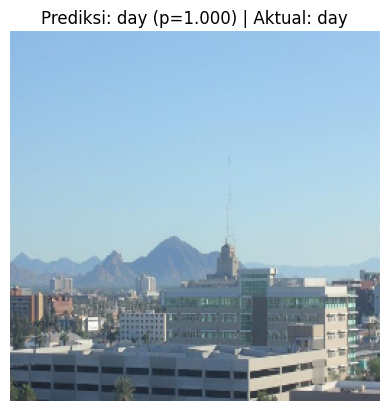

In [17]:
loaded = tf.keras.models.load_model('day_night_classifier_model.h5')

idx = 0
feat = extract_hog([X_test_img[idx]])
feat = scaler.transform(feat)
p = float(loaded.predict(feat, verbose=0)[0][0])

plt.imshow(X_test_img[idx])
plt.axis('off')
plt.title(f"Prediksi: {'day' if p > 0.5 else 'night'} (p={p:.3f}) | Aktual: {'day' if y_test[idx]==1 else 'night'}")
plt.show()

### Conclusion

* Fitur **HOG** + ANN sederhana mencapai akurasi uji **0.9375** (160 citra uji) dengan akurasi
  latih dan validasi 1.0000.
* Model **overfitting** pada dataset sekecil ini: loss validasi naik (0.0013 -> 0.0042) meski
  akurasi validasi tetap 1.0, dan akurasi uji tertinggal di 0.9375 dengan 10 kesalahan
  (8 *day* diprediksi *night*, 2 *night* diprediksi *day*).
* Standardisasi fitur penting karena nilai HOG memiliki skala yang bervariasi antar sel.
* Model tersimpan (`.h5`) dapat dimuat kembali dan dipakai untuk inferensi citra baru.